# Experiment A: Unsupervised Buzzer Detection
**Goal:** Detect suspicious accounts tanpa supervised learning

**Method:** Rule-based scoring + clustering

**Data:** 416 posts, 251 accounts (karhutla campaign)

## 1. Setup

In [11]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

print("Setup complete")

Setup complete


## 2. Load Data & Features

In [12]:
posts = pd.read_csv("../data/features/posts_with_features.csv")
posts["date"] = pd.to_datetime(posts["date"])
posts["account_id"] = posts["account_id"].astype(str)

try:
    accounts = pd.read_csv("../data/features/account_features.csv")
    print(f"Loaded: {len(posts)} posts, {len(accounts)} accounts with features")
except FileNotFoundError:
    print("account_features.csv not found, will generate...")
    accounts = None

posts.head()

Loaded: 1514 posts, 1007 accounts with features


,post_id,account_id,id,user_id,source_post_id,source_account_id,target_post_id,target_account_id,target_username,relation_type,...,is_reply,is_quote,isu,query,hashtags,n_tags,body_clean,body_len,has_url,date_only
0,2119321404298645606,1810223652115484672,2119321404298645606,1810223652115484672,2119321404298645606,1810223652115484672,2.119302e+18,4.249088e+08,Opposite6888,reply,...,True,False,wowo2,https://x.com/search?q=prabowo%20teddy&src=typ...,[],0,"Sjk skandal ini mencuat, tak pernah lagi mlht ...",255,False,2026-11-08
1,2119309075242713388,2054833974577602560,2119309075242713388,2054833974577602560,2119309075242713388,2054833974577602560,NaN,NaN,NaN,original,...,False,False,wowo2,https://x.com/search?q=prabowo%20teddy&src=typ...,[],0,Kabarnya gibran bentar lagi akan dimakzulkan.....,269,False,2026-11-08
2,2119295578949701742,2108908455482503168,2119295578949701742,2108908455482503168,2119295578949701742,2108908455482503168,2.119295e+18,1.247562e+18,yellbooks,reply,...,True,False,wowo2,https://x.com/search?q=prabowo%20teddy&src=typ...,[],0,"masa bawa prabowo, yang ada digebukin teddy",43,False,2026-11-08
3,2119282468734058548,243998004,2119282468734058548,243998004,2119282468734058548,243998004,2.119034e+18,1.437750e+18,MiskinTV_,reply,...,True,False,wowo2,https://x.com/search?q=prabowo%20teddy&src=typ...,[],0,"Yg abdi negara cuma teddy, lainnya aspri prabo...",140,False,2026-11-08
4,2119276834814820598,1275361811060019201,2119276834814820598,1275361811060019201,2119276834814820598,1275361811060019201,2.119246e+18,1.040307e+18,NenkMonica,reply,...,True,False,wowo2,https://x.com/search?q=prabowo%20teddy&src=typ...,[],0,"Ketika nyebrang ke kubu Jokowi, menjadi menter...",177,False,2026-11-08


## 3. Generate Account-Level Features

In [13]:
acc_features = posts.groupby("account_id").agg(
    username=("username", "first"),
    n_posts=("post_id", "count"),
    avg_tags=("n_tags", "mean"),
    avg_body_len=("body_len", "mean"),
    n_replies=("is_reply", "sum"),
    n_quotes=("is_quote", "sum"),
    n_originals=("relation_type", lambda x: (x == "original").sum()),
    first_post=("date", "min"),
    last_post=("date", "max"),
    followers=("followers", "first"),
    following=("following", "first")
).reset_index()

acc_features["active_hours"] = (acc_features["last_post"] - acc_features["first_post"]).dt.total_seconds() / 3600
acc_features["post_rate"] = acc_features["n_posts"] / (acc_features["active_hours"] + 0.1)
acc_features["follower_ratio"] = acc_features["followers"] / (acc_features["following"] + 1)

print(f"Account features generated: {len(acc_features)} accounts")
acc_features.describe()

Account features generated: 1007 accounts


,n_posts,avg_tags,avg_body_len,n_replies,n_quotes,n_originals,followers,following,active_hours,post_rate,follower_ratio
count,1007.000000,1007.000000,1007.000000,1007.000000,1007.000000,1007.000000,1.007000e+03,1007.000000,1007.000000,1007.000000,1007.000000
mean,1.503476,0.135811,201.952094,0.495531,0.217478,0.790467,5.590732e+04,1638.274081,95.969879,8.511148,2092.502294
std,2.082717,0.662115,301.833509,0.714609,0.584230,2.021453,4.470462e+05,2922.988257,337.190327,3.590330,21862.370840
min,1.000000,0.000000,3.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.001183,0.000000
25%,1.000000,0.000000,72.000000,0.000000,0.000000,0.000000,8.450000e+01,128.000000,0.000000,10.000000,0.485053
50%,1.000000,0.000000,130.000000,0.000000,0.000000,0.000000,5.330000e+02,424.000000,0.000000,10.000000,1.009265
75%,1.000000,0.000000,237.000000,1.000000,0.000000,1.000000,4.194500e+03,1644.000000,0.000000,10.000000,2.225753
max,34.000000,5.000000,3798.000000,9.000000,7.000000,34.000000,8.743047e+06,31392.000000,2181.643333,18.136020,344250.000000


## 4. Network Features

In [14]:
edges = posts[posts["relation_type"].isin(["reply", "quote"])]
edges = edges[["account_id", "target_account_id"]].dropna()

G = nx.from_pandas_edgelist(edges, "account_id", "target_account_id", create_using=nx.DiGraph())

in_deg = dict(G.in_degree())
out_deg = dict(G.out_degree())
pagerank = nx.pagerank(G)

# Add to features
acc_features["in_degree"] = acc_features["account_id"].map(in_deg).fillna(0)
acc_features["out_degree"] = acc_features["account_id"].map(out_deg).fillna(0)
acc_features["pagerank"] = acc_features["account_id"].map(pagerank).fillna(0)

print("Network features added")
print(acc_features[["username", "in_degree", "out_degree", "pagerank"]].head(10))

Network features added
          username  in_degree  out_degree  pagerank
0     FathraNazrul        0.0         0.0  0.000000
1          rasjawa        0.0         0.0  0.000000
2    Squidward_san        0.0         3.0  0.000628
3       soobinungu        0.0         1.0  0.000628
4          adarwis        0.0         0.0  0.000000
5         toamajid        0.0         1.0  0.000628
6      moccaronies        0.0         1.0  0.000628
7  troides_helenaa        0.0         1.0  0.000628
8       Yuri_Anyya        0.0         0.0  0.000000
9   Hidupsebagai62        0.0         0.0  0.000000


## 5. Rule-Based Buzzer Score

In [15]:
def normalize(series):
    min_val = series.min()
    max_val = series.max()
    if max_val == min_val:
        return pd.Series(0, index=series.index)
    return (series - min_val) / (max_val - min_val)

acc_features["score_post_rate"] = normalize(acc_features["post_rate"])
acc_features["score_high_tags"] = normalize(acc_features["avg_tags"])
acc_features["score_short_content"] = 1 - normalize(acc_features["avg_body_len"])  # Lower = more suspicious
acc_features["score_high_engagement"] = normalize(acc_features["out_degree"])
acc_features["score_low_follower_ratio"] = 1 - normalize(acc_features["follower_ratio"].clip(0, 10))  # Clip outliers

acc_features["buzzer_score"] = (
    0.25 * acc_features["score_post_rate"] +
    0.20 * acc_features["score_high_tags"] +
    0.15 * acc_features["score_short_content"] +
    0.25 * acc_features["score_high_engagement"] +
    0.15 * acc_features["score_low_follower_ratio"]
)

print("Buzzer scores calculated")
print("\nScore distribution:")
print(acc_features["buzzer_score"].describe())

Buzzer scores calculated

Score distribution:
count    1007.000000
mean        0.394670
std         0.077470
min         0.064463
25%         0.374883
50%         0.425357
75%         0.443764
max         0.623137
Name: buzzer_score, dtype: float64


## 6. Top Suspicious Accounts

=== TOP 30 SUSPICIOUS ACCOUNTS ===
       username  n_posts  post_rate  avg_tags  avg_body_len  out_degree  follower_ratio  buzzer_score
    posrondart9        1     10.000       5.0       207.000         0.0           0.443         0.623
      asaprosul        1     10.000       5.0       106.000         1.0           3.766         0.598
    FITRI688212        1     10.000       4.0       175.000         0.0           0.268         0.587
      mzk716524        1     10.000       5.0       114.000         0.0           5.130         0.556
bukan_fufufafa_        1     10.000       5.0      1851.000         0.0           1.043         0.549
   Up_informasi        1     10.000       3.0       302.000         0.0           0.154         0.544
      Addaily11        1     10.000       5.0      2287.000         0.0           0.537         0.540
   jurnalkencan       12      0.016       0.0       203.167        12.0           0.863         0.529
    MarahIchsan        2     18.136       0.0  

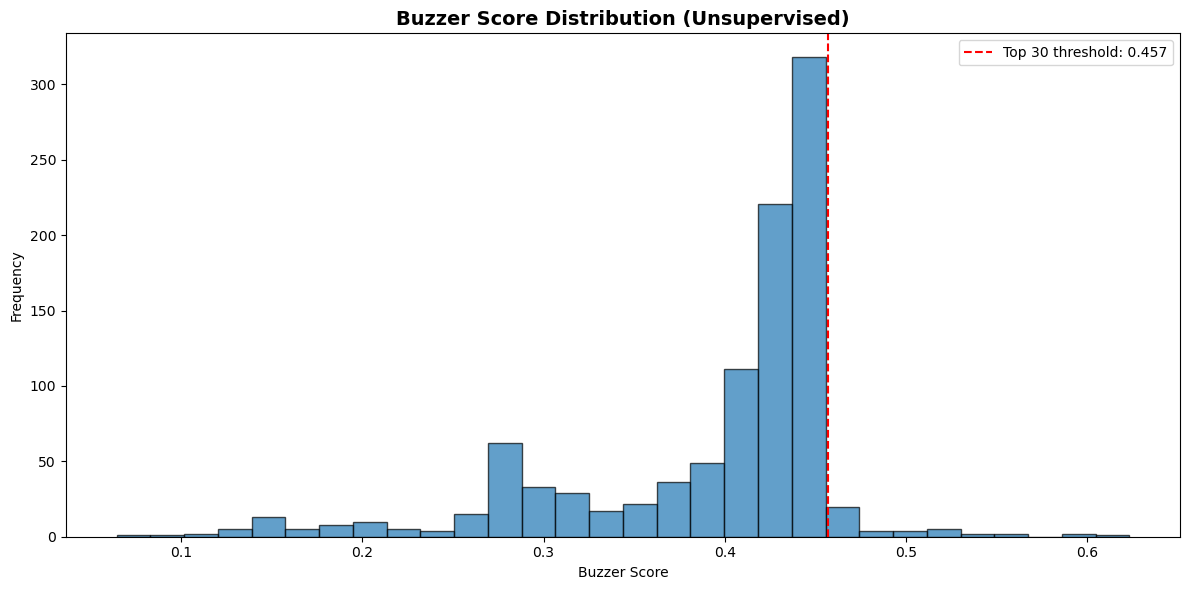

In [16]:
suspicious = acc_features.nlargest(30, "buzzer_score")[
    ["username", "n_posts", "post_rate", "avg_tags", "avg_body_len", 
     "out_degree", "follower_ratio", "buzzer_score"]
].round(3)

print("=== TOP 30 SUSPICIOUS ACCOUNTS ===")
print(suspicious.to_string(index=False))

fig, ax = plt.subplots(figsize=(12, 6))
ax.hist(acc_features["buzzer_score"], bins=30, edgecolor='black', alpha=0.7)
ax.axvline(suspicious["buzzer_score"].min(), color='red', linestyle='--', 
           label=f'Top 30 threshold: {suspicious["buzzer_score"].min():.3f}')
ax.set_xlabel("Buzzer Score")
ax.set_ylabel("Frequency")
ax.set_title("Buzzer Score Distribution (Unsupervised)", fontsize=14, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig("../output/unsupervised_scores.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Feature Importance (Component Analysis)


=== FEATURE COMPARISON: Top 30 vs Others ===
          post_rate  avg_tags  avg_body_len  out_degree  follower_ratio
is_top30                                                               
False          8.44      0.08        197.04        0.68         2151.65
True          10.67      1.80        362.02        0.93          166.20


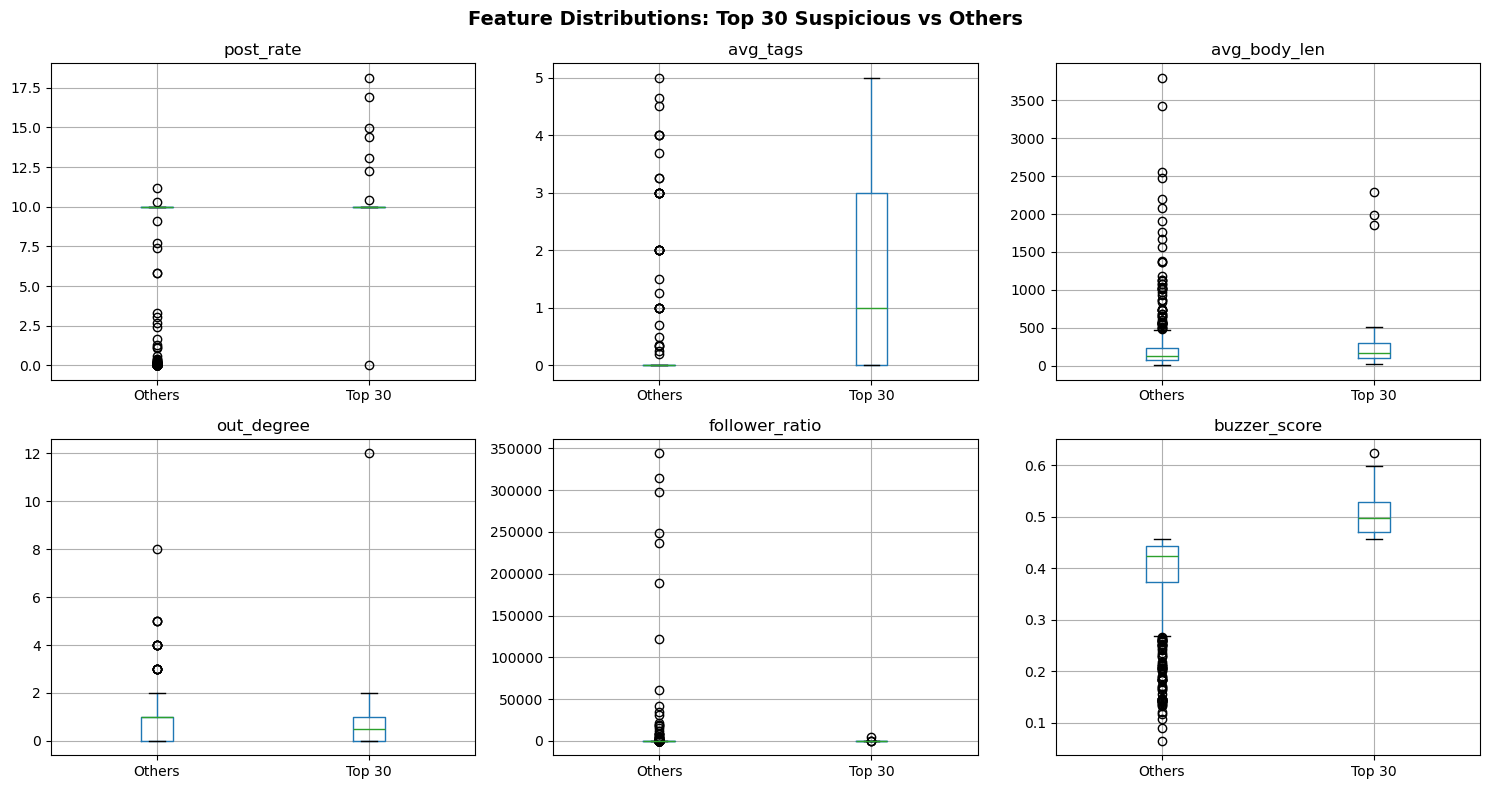

In [17]:
top30_ids = suspicious["username"].tolist()
acc_features["is_top30"] = acc_features["username"].isin(top30_ids)

comparison = acc_features.groupby("is_top30")[[
    "post_rate", "avg_tags", "avg_body_len", "out_degree", "follower_ratio"
]].mean()

print("\n=== FEATURE COMPARISON: Top 30 vs Others ===")
print(comparison.round(2))

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
features_to_plot = ["post_rate", "avg_tags", "avg_body_len", "out_degree", "follower_ratio", "buzzer_score"]

for idx, feature in enumerate(features_to_plot):
    ax = axes[idx // 3, idx % 3]
    acc_features.boxplot(column=feature, by="is_top30", ax=ax)
    ax.set_title(feature)
    ax.set_xlabel("")
    ax.set_xticklabels(["Others", "Top 30"])

plt.suptitle("Feature Distributions: Top 30 Suspicious vs Others", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("../output/unsupervised_feature_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Export for Manual Review

In [ ]:
import os
os.makedirs("../data/labels", exist_ok=True)

review_df = suspicious.copy()
review_df["label"] = ""  
review_df["notes"] = "" 

review_df.to_csv("../data/labels/roysuryotop30_for_review.csv", index=False)
print("Exported: data/labels/top30_for_review.csv")

random_accounts = acc_features[~acc_features["is_top30"]].sample(20, random_state=42)[
    ["username", "n_posts", "post_rate", "avg_tags", "avg_body_len", "buzzer_score"]
]
random_accounts["label"] = ""
random_accounts["notes"] = ""
random_accounts.to_csv("../data/labels/roysuryorandom20_for_review.csv", index=False)
print("Exported: data/labels/random20_for_review.csv")

acc_features.to_csv("../data/features/roysuryoaccount_features_with_scores.csv", index=False)
print("Exported: data/features/account_features_with_scores.csv")


Exported: data/labels/top30_for_review.csv
Exported: data/labels/random20_for_review.csv
Exported: data/features/account_features_with_scores.csv
